# La diversification résiste-t-elle aux baisses de marché ?

**Projet Python ENSAE — Rapport final**

## Résumé

On compare six portefeuilles pendant les baisses des grandes actions américaines. Sur les sept cycles retenus, les quatre allocations qui associent actions et autres classes d'actifs perdent moins que la référence, mais restent perdantes. La diversification géographique entre actions protège de façon plus irrégulière. Pour comprendre cette différence, on introduit un témoin à rendement nul : il montre qu'une partie de la protection vient simplement du fait de détenir moins d'actions. Enfin, l'apport supplémentaire des obligations varie selon les épisodes et devient défavorable en 2022.

## 1. Introduction : que signifie « résister » ?

Le contraste entre 2008 et 2022 donne un point de départ à notre problématique. En 2008, on sait que les obligations progressent pendant que les actions chutent, mais en 2022, les deux baissent. On cherche donc à savoir si une protection observée dans une crise se retrouve dans les autres. Pour y répondre, on distingue "perdre moins que la référence" et "préserver son capital pendant la baisse".

On prend comme référence SPY, un fonds qui représente les grandes actions américaines. On regarde ensuite ce que changent l'ajout d'autres pays, puis celui d'obligations ou d'or, avec des allocations fixées pour toute la période (à savoir que les sorties du rapport sont enregistrées pour la lecture).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

candidats = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidats
             if (p / "fonctions/scraping.py").is_file()
             and (p / "data/raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir le notebook depuis le dossier du projet")
sys.path.insert(0, str(ROOT))

from fonctions.scraping import TICKERS, fetch_yahoo, fetch_fred
from fonctions.audit import auditer_prix, auditer_cpi
from fonctions.analyse import (
    ALLOCATIONS, simuler_allocations, capital_et_recul, indicateurs,
    pertes_en_baisse, reperer_episodes, rendements_episodes,
    contexte_inflation, comparer_decennies, comparer_seuils, comparer_temoin,
)
from fonctions.graphiques import tracer_capital, tracer_reculs, tracer_episodes, tracer_correlations


## 2. Données et préparation

On utilise six **ETF**, des fonds cotés en bourse : SPY pour les actions américaines, EFA pour les actions développées hors États-Unis et Canada, EEM pour les actions émergentes, IEF pour les obligations du Trésor américain à 7–10 ans, SHY pour celles à 1–3 ans et GLD pour l'or.

Une action représente une part de propriété d'une entreprise ; une obligation est une dette de son émetteur. Les fonds obligataires reçoivent des intérêts, alors que l'or ne procure pas ce type de revenu.

On conserve les vingt années **2006–2025**, avec la clôture du **30 décembre 2005** pour calculer le premier rendement. La fonction `fetch_yahoo` de `scraping.py` regroupe les téléchargements avec `yf.download`. Elle utilise `auto_adjust=False` pour conserver `Adj Close` et `Close` séparément, et une fin exclusive au 1er janvier 2026.

Les cours ajustés prennent en compte les distributions et les divisions d'actions. Par exemple, une part vaut 100, verse 2 puis cote 98 : le cours baisse mais la valeur totale détenue reste 100. On utilise les ajustements pour approcher des distributions réinvesties, sans les ajouter une seconde fois.

Pour l'inflation, on utilise l'indice américain des prix à la consommation corrigé des variations saisonnières. **La sauvegarde fournie vient de la collecte BLS du projet, série `CUSR0000SA0`, convertie en Parquet sans changer ses valeurs.** La colonne est nommée `CPIAUCSL` pour correspondre à la série diffusée par FRED. Une nouvelle collecte avec `fetch_fred` passe par l'API FRED et nécessite une clé personnelle ; elle peut donner des valeurs révisées.

L'inflation décrit le contexte sans corriger les rendements ni déterminer les allocations. Le tableau suivant indique la provenance réelle des sauvegardes utilisées.


In [2]:
informations = json.loads((ROOT / "data/raw/collecte.json").read_text())
sources = pd.DataFrame(informations["sources"])
display(sources)


,fichier,source,contenu,collecte_utc
0,asset_prices.parquet,Yahoo Finance via yfinance,cours ajustés des six ETF,2026-11-26
1,asset_closes.parquet,Yahoo Finance via yfinance,cours de clôture des six ETF,2026-11-26
2,CPIAUCSL.parquet,BLS API v1 série CUSR0000SA0,indice CPI corrigé des variations saisonnières...,2026-11-26


### Collecter une fois puis relire les fichiers

On conserve trois fichiers Parquet : les cours ajustés, les clôtures et l'indice des prix. Ils reprennent les valeurs de la collecte fournie dans le projet avant cette adaptation. Changer le format ne constitue pas un nouveau téléchargement.

`fetch_yahoo()` et `fetch_fred()` relisent les sauvegardes lorsqu'elles sont présentes. Les mêmes données produisent ainsi les mêmes résultats. Si les fichiers manquent, les fonctions téléchargent les données ; `actualiser=True` permet aussi de demander explicitement une nouvelle collecte. Cette actualisation peut modifier les chiffres et demande une connexion ainsi qu'une clé FRED pour l'inflation.


In [3]:
for nom in sources["fichier"]:
    assert (ROOT / "data/raw" / nom).is_file(), nom
print("Les trois sauvegardes de données sont disponibles")


Les trois sauvegardes de données sont disponibles


### Auditer les cours

`auditer_prix` vérifie les dates, les doublons, les valeurs manquantes et les prix non positifs ou infinis. On utilise uniquement un calendrier complet commun aux six fonds, sans remplacer un prix manquant par le précédent. Si un téléchargement est incomplet, l'audit arrête le notebook pour qu'on examine le problème.


In [4]:
prix = fetch_yahoo()
qualite = auditer_prix(prix)
assert str(prix.index[0].date()) == "2005-12-30"
assert str(prix.index[-1].date()) == "2025-12-31"
display(qualite)
print(f"{len(prix)} dates communes et {len(prix) - 1} rendements")


,première date,dernière date,séances,manquants,prix <= 0
SPY,2005-12-30,2025-12-31,5032,0,0
EFA,2005-12-30,2025-12-31,5032,0,0
EEM,2005-12-30,2025-12-31,5032,0,0
IEF,2005-12-30,2025-12-31,5032,0,0
GLD,2005-12-30,2025-12-31,5032,0,0
SHY,2005-12-30,2025-12-31,5032,0,0


5032 dates communes et 5031 rendements


On obtient **5 032 dates communes** aux six séries, sans prix manquant, on ne retire donc aucune date et il reste **5 031 rendements**, puisqu'il faut deux prix successifs pour calculer une variation.

On peut ensuite regarder l'effet des distributions : le tableau compare les gains cumulés sur vingt ans avec les cours ajustés et avec les seuls cours de clôture. Les divisions d'actions sont prises en compte dans les deux séries (les gains affichés ne sont pas des rendements annuels).

In [5]:
clotures = pd.read_parquet(ROOT / "data/raw/asset_closes.parquet")
clotures = clotures.loc[prix.index, prix.columns]
auditer_prix(clotures)
comparaison = pd.DataFrame({
    "rendement ajusté (%)": (prix.iloc[-1] / prix.iloc[0] - 1) * 100,
    "sans distributions (%)": (clotures.iloc[-1] / clotures.iloc[0] - 1) * 100,
})
comparaison.round(2)


,rendement ajusté (%),sans distributions (%)
SPY,693.38,447.68
EFA,190.60,61.59
EEM,180.32,85.98
IEF,92.73,14.60
GLD,668.34,668.34
SHY,48.63,3.25


Pour SPY, on passe d'un gain de **447,68 %** sans distributions à **693,38 %** avec ajustements. L'écart est aussi important pour IEF : **14,60 %** contre **92,73 %**. On voit donc l'importance des revenus versés pour les obligations. Ex : pour GLD, qui ne distribue rien dans cet historique, les deux mesures coïncident.

### Passer du niveau des prix à l'inflation

L'indice BLS, base 1982–1984 = 100, donne un niveau de prix. Pour obtenir l'inflation annuelle, on calcule `100 × (indice du mois / indice du même mois un an avant − 1)`. Une inflation de 3 % signifie une hausse des prix de 3 % en douze mois. Les données de 2005 permettent de calculer les premières variations de 2006.

On utilise un calendrier mensuel complet avant de calculer la variation sur douze mois. **Octobre 2025 manque dans la sauvegarde fournie** : on le laisse sans valeur. Ce mois sera exclu de la comparaison selon l'inflation, mais ses rendements de marché resteront dans l'analyse.

In [6]:
cpi = fetch_fred()
display(auditer_cpi(cpi))
inflation = (100 * cpi["CPIAUCSL"].pct_change(12, fill_method=None)).loc["2006-01":]
inflation.index = inflation.index.to_period("M")
inflation.name = "inflation_pct"
print("Mois sans inflation annuelle :", inflation.index[inflation.isna()].astype(str).tolist())


,première date,dernière date,nombre de mois,mois sans indice
0,2005-01-01,2025-12-01,252,1


Mois sans inflation annuelle : ['2025-10']


## 3. Méthode : allocations, rééquilibrage et indicateurs

On fixe d'abord les poids cibles, c-a-d la part du capital à placer dans chaque actif. **US 60/40** signifie 60 % en SPY et 40 % en IEF. **Monde 60/40** place 60 % dans le panier actions monde et 40 % en IEF, soit 36 % SPY, 15 % EFA et 9 % EEM.

Chacune de nos comparaisons répond à une question, d'où les choix suivants :

| Comparaison | Question |
|---|---|
| Actions monde / Actions US | Ajouter des pays réduit-il les pertes ? |
| US 60/40 / Actions US | Que change le remplacement d'actions par des obligations ? |
| Monde 60/40 / Actions monde | Retrouve-t-on cet effet avec des actions internationales ? |
| US 50/30/20 / US 60/40 | Que change l'ajout d'or associé à une moindre part actions ? |
| US 60/40 court / US 60/40 | À même cible actions, quel rôle joue la durée des obligations ? |

Pour le panier actions monde, on choisit **60 % SPY, 25 % EFA et 15 % EEM**. Cette répartition garde les États-Unis majoritaires sans reproduire exactement un indice mondial. Le 50/30/20 change à la fois les parts actions, obligations et or : on ne pourra donc pas attribuer son résultat au seul or.

In [7]:
poids_cibles = pd.DataFrame(ALLOCATIONS).T.fillna(0)
display((100 * poids_cibles).round(0).rename_axis("poids cibles (%)"))

,SPY,EFA,EEM,IEF,GLD,SHY
poids cibles (%),,,,,,
Actions US,100.0,0.0,0.0,0.0,0.0,0.0
Actions monde,60.0,25.0,15.0,0.0,0.0,0.0
US 60/40,60.0,0.0,0.0,40.0,0.0,0.0
Monde 60/40,36.0,15.0,9.0,40.0,0.0,0.0
US 50/30/20,50.0,0.0,0.0,30.0,20.0,0.0
US 60/40 court,60.0,0.0,0.0,0.0,0.0,40.0


### Suivre la valeur des portefeuilles

On suppose que les portefeuilles sont investis depuis fin 2005, sans apport ni retrait. On revient aux poids cibles à la clôture de la dernière séance de chaque mois, avant le rendement de la première séance du mois suivant. Entre deux rééquilibrages, les poids évoluent avec les cours.

Par exemple, si on répartit un capital de 100 entre 60 d'actions et 40 d'un autre actif, puis que les actions gagnent 10 % pendant que l'autre actif reste stable, les positions valent 66 et 40. Les actions représentent donc 66/106, soit **62,26 %** du portefeuille. Pour revenir à 60/40, on répartit les 106 atteints selon cette cible : on ne repart pas de 100 et on conserve le gain.

Pour écrire ce calcul, on note $P^{aj}_{i,t}$ le prix ajusté de l'actif $i$ à la séance $t$, $r_{i,t}$ son rendement et $w_{i,t-1}$ sa part dans le portefeuille avant la variation. On obtient le rendement du portefeuille $r_{p,t}$ puis ses nouveaux poids :

$$r_{i,t}=\frac{P^{aj}_{i,t}}{P^{aj}_{i,t-1}}-1,\qquad r_{p,t}=\sum_i w_{i,t-1}r_{i,t},\qquad w_{i,t}=\frac{w_{i,t-1}(1+r_{i,t})}{1+r_{p,t}}.$$

Si on remettait les poids à leur cible chaque jour, on simulerait un rééquilibrage quotidien. Ici, on garde la même règle mensuelle sur toute la période, sans l'adapter aux crises. Les frais internes des fonds sont déjà reflétés dans les cours ; on ne simule pas la fiscalité, les frais de transaction ou le levier.

### Trois indicateurs complémentaires

On fait partir le capital normalisé de $V_0=1$, puis on le calcule avec $V_t=\prod_{s=1}^{t}(1+r_{p,s})$. Pour comparer les trajectoires, on utilise trois indicateurs, avec $T$ la dernière séance et $Y$ la durée totale en années :

| Indicateur | Calcul | Interprétation |
|---|---|---|
| Rendement annualisé | $V_T^{1/Y}-1$ | Taux annuel constant donnant le même capital final, et non gain de chaque année |
| Volatilité annualisée | Écart-type des rendements quotidiens, correction $n-1$ pour $n$ observations, multiplié par $\sqrt{252}$ | Ampleur des fluctuations, hausses et baisses comprises ; 252 est une convention de séances par an |
| Recul maximal (*maximum drawdown*) | $\min_t[V_t/\max_{0\leq s\leq t}V_s-1]$ | Plus forte perte depuis un sommet antérieur ; de 100 à 80, le recul est de 20 % |


In [8]:
rendements = simuler_allocations(prix)
capital, recul = capital_et_recul(rendements, prix.index[0])

### Contrôler le portefeuille de référence

On vérifie que les allocations totalisent 100 % et que le portefeuille entièrement investi en SPY suit son actif. Les diagnostics des sources sont regroupés dans `audit.py`. Ces contrôles simples arrêtent le notebook si une condition n'est pas satisfaite.


In [9]:
assert len(rendements) == len(prix) - 1
assert rendements.index.equals(prix.index[1:])
np.testing.assert_allclose(poids_cibles.sum(axis=1), 1)
np.testing.assert_allclose(rendements["Actions US"], prix["SPY"].pct_change(fill_method=None).iloc[1:])
np.testing.assert_allclose(capital["Actions US"], prix["SPY"] / prix["SPY"].iloc[0])
print("Calendrier et portefeuille de référence vérifiés")


Calendrier et portefeuille de référence vérifiés


## 4. Résultats : performance globale, jours de baisse et cycles

In [10]:
synthese = indicateurs(rendements, capital, recul)
display(synthese.round(2))


,rendement annualisé (%),volatilité annualisée (%),recul maximal (%)
Actions US,10.91,19.39,-55.19
Actions monde,8.85,20.26,-57.22
US 60/40,8.19,10.87,-32.58
Monde 60/40,7.00,11.33,-34.66
US 50/30/20,9.12,10.08,-27.00
US 60/40 court,7.57,11.27,-35.29


### Croissance du capital et fluctuations sur vingt ans

Dans le tableau, SPY a le rendement annualisé le plus élevé (**10,91 %**). Le panier actions monde atteint **8,85 %**, avec une volatilité de **20,26 %**, contre **19,39 %** pour SPY. On voit donc que, sur cette période et avec ces poids, l'ajout de pays n'améliore ni la croissance finale ni les fluctuations.

Avec le US 60/40, on obtient **8,19 %** de rendement annualisé pour **10,87 %** de volatilité ; avec le US 50/30/20, **9,12 %** et **10,08 %**. Ces allocations fluctuent moins que SPY, avec un rendement inférieur. On doit encore examiner les pertes intermédiaires.

Le graphique suit ces trajectoires à partir de **100 pour chaque portefeuille** fin 2005. L'échelle verticale est logarithmique : un doublement de 100 à 200 occupe la même hauteur qu'un doublement de 200 à 400.

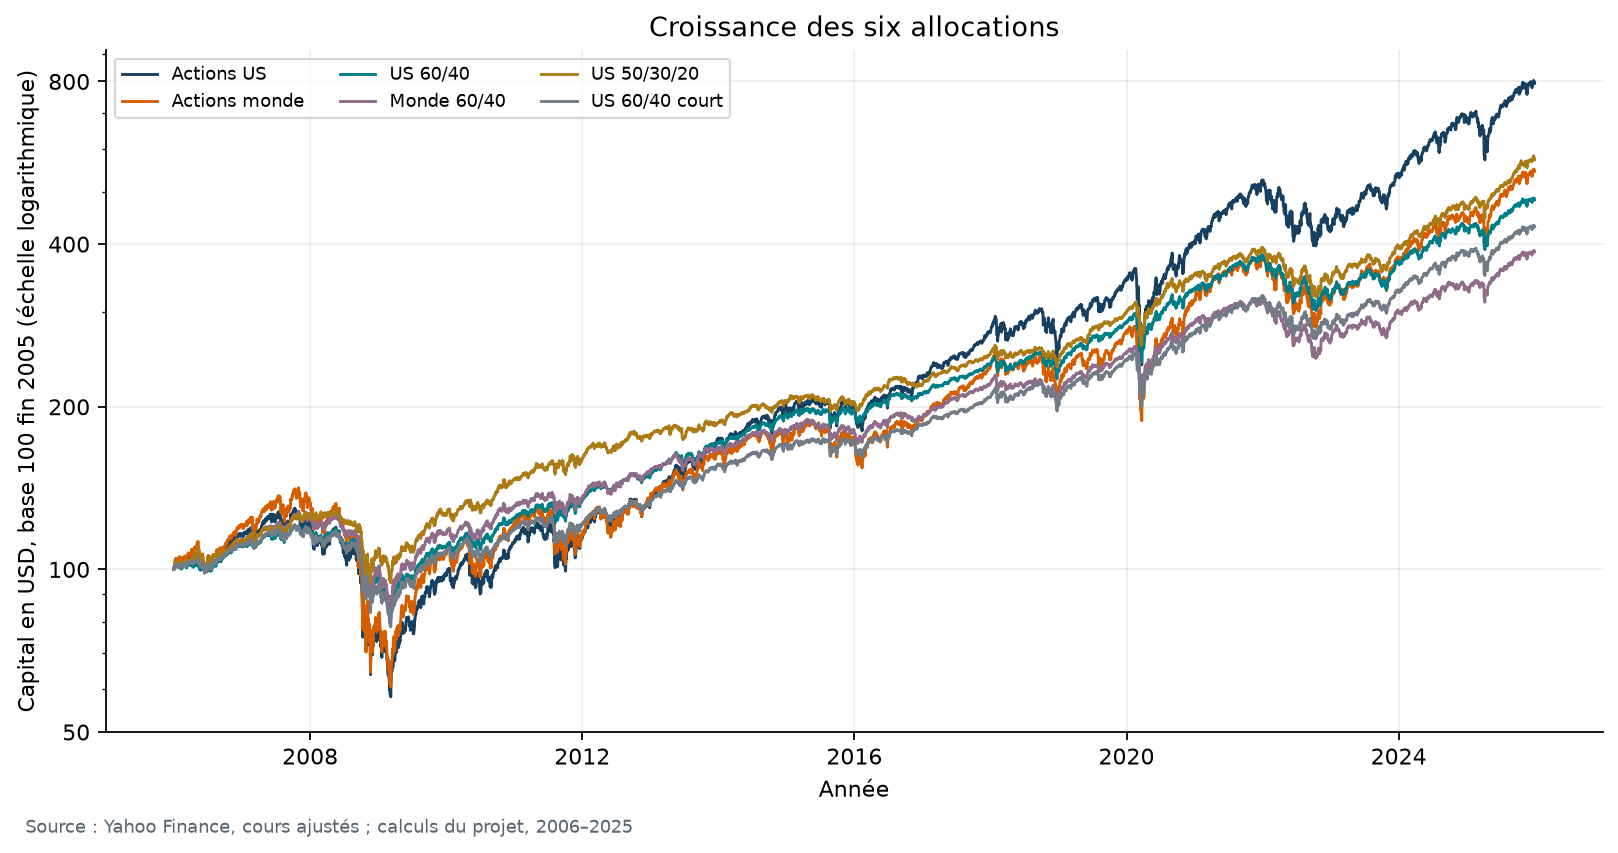

In [11]:
tracer_capital(capital)

La croissance finale ne montre pas toujours les chutes traversées. On regarde donc l'écart au **meilleur niveau déjà atteint par chaque portefeuille**. Sur le graphique suivant, zéro correspond à un sommet et −20 % à un capital situé 20 % en dessous. Quand la courbe revient à zéro, le portefeuille a récupéré ce sommet.

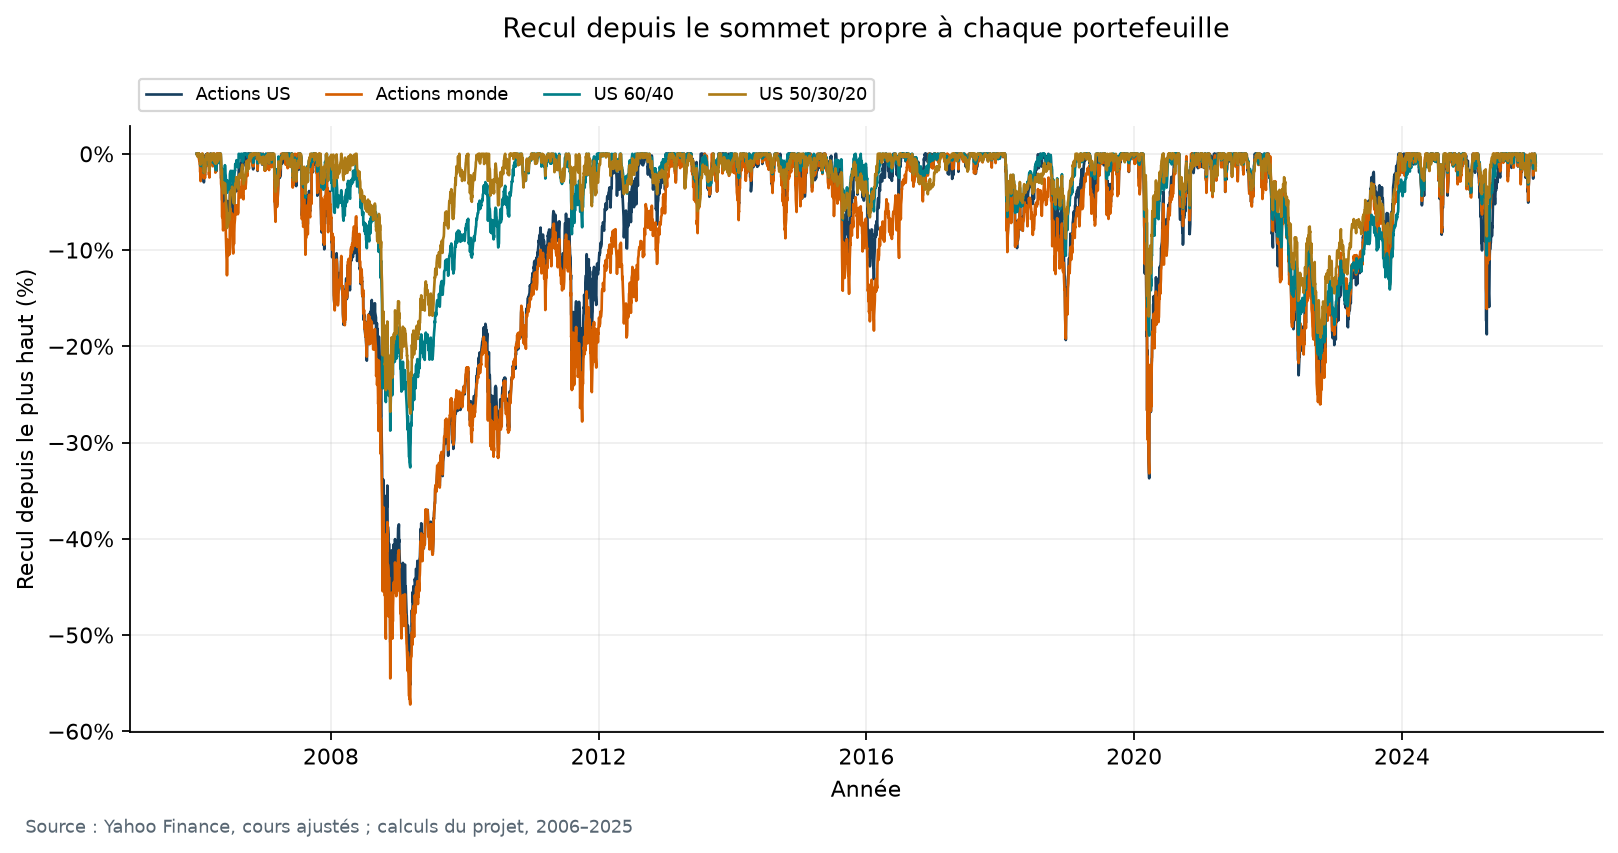

In [12]:
tracer_reculs(recul)

Le recul maximal de SPY atteint **−55,19 %**. Autrement dit, un capital de 100 à son sommet ne vaut plus que **44,81** au creux. On trouve **−32,58 %** pour le US 60/40 et **−27,00 %** pour le US 50/30/20, contre **−57,22 %** pour les actions monde. Les pertes des allocations mixtes restent donc importantes.

Chaque recul est mesuré depuis le sommet propre au portefeuille : ce n'est pas forcément une perte depuis l'investissement initial. On affiche quatre courbes pour la lisibilité ; le tableau couvre les six allocations.

### Que se passe-t-il quand SPY baisse ?

#### Les séances négatives

On sélectionne maintenant les dates où SPY baisse pour comparer les mêmes séances. On calcule alors le rendement moyen et les proportions de séances où chaque allocation fait **strictement mieux que SPY** ou reste **sans perte**. Ces jours sont identifiés après coup : les fréquences décrivent l'historique, pas une prévision.

In [13]:
print(f"{(rendements['Actions US'] < 0).sum()} séances où SPY baisse")
pertes_en_baisse(rendements).round(2)

2242 séances où SPY baisse


,rendement moyen (%),mieux que SPY (%),sans perte (%)
Actions US,-0.82,0.00,0.00
Actions monde,-0.84,47.59,9.19
US 60/40,-0.45,86.44,11.86
Monde 60/40,-0.46,81.31,14.72
US 50/30/20,-0.38,83.32,19.54
US 60/40 court,-0.48,96.83,2.68


Sur les **2 242 séances négatives** de SPY, sa perte moyenne est de **−0,822 %**, contre **−0,448 %** pour le US 60/40 et **−0,382 %** pour le US 50/30/20. Le 60/40 fait mieux que SPY dans **86,44 %** de ces séances, mais reste sans perte dans seulement **11,86 %**. On retrouve une atténuation fréquente, sans éviter la perte. Pour SPY lui-même, la colonne « mieux que SPY » vaut logiquement zéro.

Les actions monde perdent en moyenne **0,844 %**. On n'observe donc pas de protection géographique dans cette comparaison moyenne. Mais sélectionner les jours négatifs de SPY met en avant les allocations moins exposées à cet actif. Le témoin de la partie 5 permettra de préciser cet effet.

#### Les cycles de baisse

Une séance isolée ne décrit cependant pas une longue baisse. On suit donc SPY depuis son dernier sommet jusqu'à son premier retour à ce niveau, en retenant les cycles dont le recul atteint **10 %**. Le « creux » est le minimum de SPY dans le cycle ; une récupération absente signalerait un cycle encore ouvert à fin 2025.

On compare les rendements **du sommet au creux de SPY, aux mêmes dates pour tous**. Ce calcul diffère du recul maximal propre à chaque allocation, dont le sommet ou le creux peuvent survenir ailleurs.

In [14]:
episodes = reperer_episodes(capital["Actions US"])
performance_episodes = rendements_episodes(capital, episodes)
episodes


,sommet,creux,recuperation
0,2007-10-09,2009-03-09,2012-08-16
1,2015-07-20,2016-02-11,2016-04-18
2,2018-01-26,2018-02-08,2018-08-06
3,2018-09-20,2018-12-24,2019-04-12
4,2020-02-19,2020-03-23,2020-08-10
5,2022-01-03,2022-10-12,2023-12-13
6,2025-02-19,2025-04-08,2025-06-26


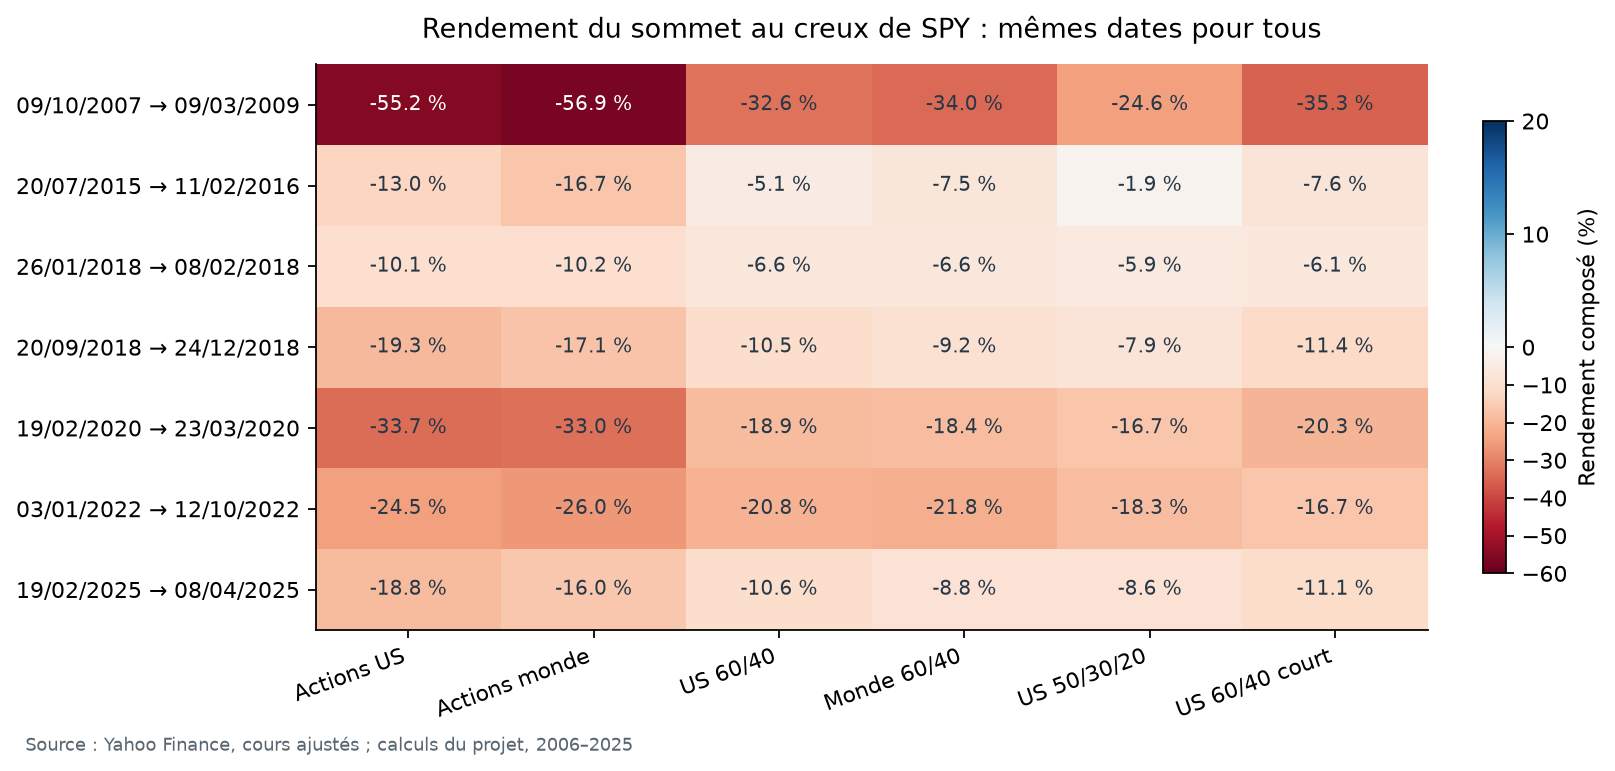

In [15]:
tracer_episodes(performance_episodes, episodes)

Chaque ligne compare les portefeuilles pendant une même baisse de SPY. Les quatre allocations entre classes d'actifs perdent moins que lui dans **7 cycles sur 7**, mais restent négatives. Les actions monde font mieux dans **3 cas sur 7**. Une case plus claire correspond donc à une perte moins forte, pas à un gain.

On voit aussi que la protection varie beaucoup. En 2007–2009, SPY perd **55,19 %** et le US 60/40 **32,57 %**. En 2022, les pertes sont de **24,50 %** et **20,77 %** : l'écart est bien plus faible. Le 60/40 court y perd **16,67 %**, ce qui pousse à regarder la durée des obligations détenues.

Les sept cycles sont récupérés à fin 2025. La règle regroupe les rechutes avant récupération : les corrections de 2010 et 2011 restent dans le cycle 2007–2012. On ne recense donc pas séparément toutes les corrections historiques.

## 5. Approfondissement : rôle des autres actifs et contexte d'inflation

### Un témoin à même part actions cible

On peut alors se demander quelle part de la protection vient simplement de détenir moins d'actions. Par exemple, sur une séance qui commence aux poids cibles, si SPY perd 10 % et le reste ne bouge pas, une allocation 60/40 perd 6 %, sans qu'un autre actif ait gagné.

Pour le préciser, on construit un **témoin théorique : 60 % SPY et 40 % poche à rendement nul**, avec le même rééquilibrage mensuel. Cette poche reste constante par hypothèse ; elle ne représente ni un fonds monétaire observé ni SHY.

La dernière colonne du tableau donne « US 60/40 moins témoin », en points de pourcentage, sur les mêmes dates sommet–creux de SPY. Si l'écart est positif, remplacer la poche constante par IEF a amélioré le résultat ; s'il est négatif, cela l'a dégradé. Les deux portefeuilles ont la même cible actions, mais leurs poids effectifs peuvent évoluer différemment entre les rééquilibrages.

In [16]:
comparaison_temoin = comparer_temoin(prix, rendements, episodes)
comparaison_temoin.set_index(["sommet", "creux"]).round(2)

,,US 60/40 (%),Témoin nul (%),écart 60/40 − témoin (points)
sommet,creux,,,
2007-10-09,2009-03-09,-32.57,-37.54,4.97
2015-07-20,2016-02-11,-5.06,-7.84,2.78
2018-01-26,2018-02-08,-6.57,-6.12,-0.45
2018-09-20,2018-12-24,-10.55,-11.79,1.24
2020-02-19,2020-03-23,-18.89,-21.08,2.20
2022-01-03,2022-10-12,-20.77,-15.11,-5.66
2025-02-19,2025-04-08,-10.56,-11.53,0.98


In [17]:
assert comparaison_temoin["sommet"].equals(episodes["sommet"])
assert comparaison_temoin["creux"].equals(episodes["creux"])
np.testing.assert_allclose(
    comparaison_temoin["écart 60/40 − témoin (points)"],
    comparaison_temoin["US 60/40 (%)"] - comparaison_temoin["Témoin nul (%)"],
)
print("Dates et écarts du témoin vérifiés")


Dates et écarts du témoin vérifiés


On constate qu'IEF améliore le résultat dans **cinq cycles sur sept**. En 2007–2009, le US 60/40 perd **32,57 %**, contre **37,54 %** pour le témoin : les obligations apportent **4,97 points** supplémentaires.

En 2022, le résultat s'inverse. Le 60/40 perd **20,77 %**, contre **15,11 %** pour le témoin, soit **5,66 points de moins**. Le 60/40 fait donc mieux que SPY, mais moins bien que la poche constante à même cible actions.

Ce témoin aide à distinguer la moindre exposition aux actions de l'apport d'IEF. Il ne donne pas le rendement monétaire réellement accessible. L'écart inclut aussi la dérive des poids et le rééquilibrage : on n'isole pas un effet causal de corrélation.

### Les actifs évoluent-ils ensemble ?

Pour comprendre ces écarts, on regarde la **corrélation de Pearson**, qui mesure la liaison linéaire entre les rendements. Près de +1, ils évoluent généralement dans le même sens ; près de −1, en sens opposés. Une valeur proche de zéro ne garantit ni indépendance ni absence de risque. On calcule ici la matrice sur toutes les séances de la période ; sa diagonale vaut 1.

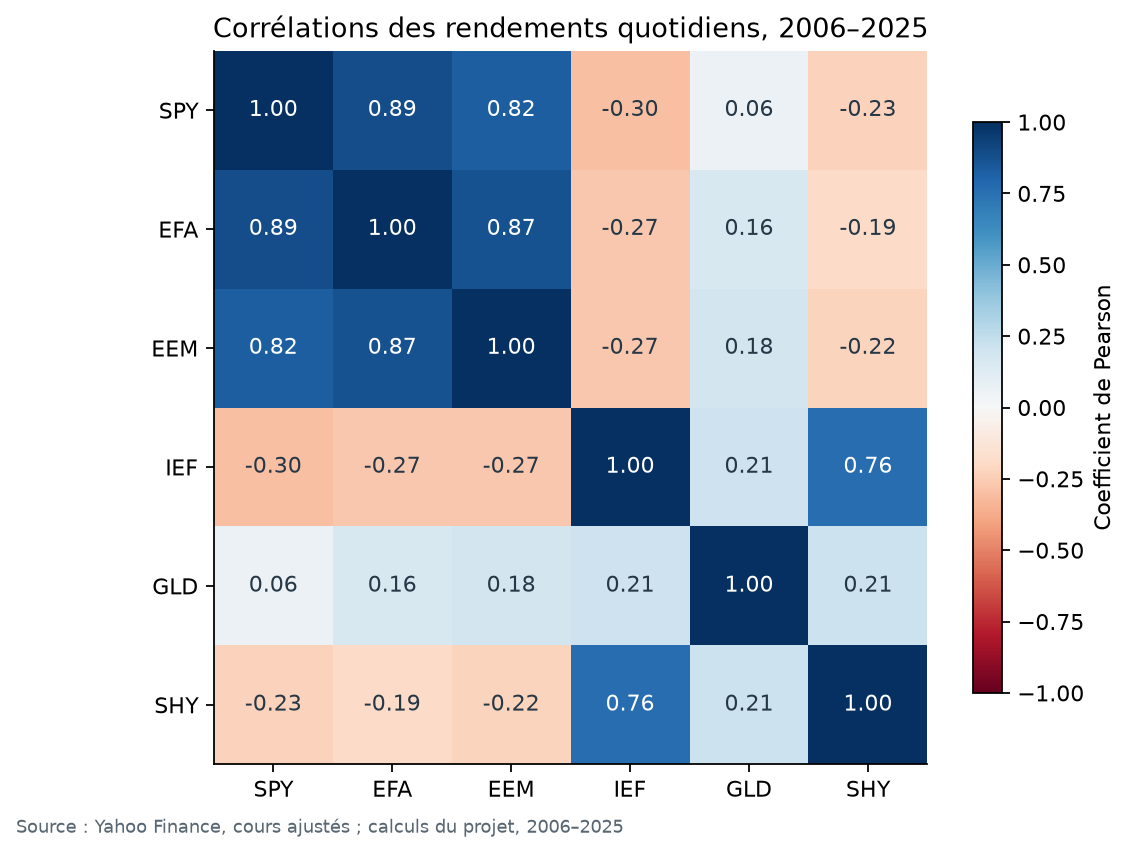

In [18]:
rendements_actifs = prix.pct_change(fill_method=None).iloc[1:]
correlations = rendements_actifs.corr()
tracer_correlations(correlations)

Les corrélations quotidiennes de SPY avec EFA et EEM sont élevées (**0,89** et **0,82**). Les marchés actions restent donc fortement liés, ce qui éclaire la protection géographique irrégulière. Avec GLD (**0,06**) et IEF (**−0,30**), on trouve des mouvements plus différents de ceux de SPY, sans que cela promette une compensation à chaque chute.

### Comparer les mois selon l'inflation

Pour voir si le contexte change cette relation, on compose les rendements quotidiens en rendements mensuels, puis on les rapproche de l'inflation annuelle du même mois. On sépare les mois d'inflation **inférieure à 3 %** des autres. Ce seuil arrondi sert de repère descriptif ; on ne l'optimise pas sur les résultats.

La première table donne les effectifs et la corrélation mensuelle SPY–IEF par groupe. On regarde ensuite les rendements annuels de 2008 et 2022 pour illustrer le contraste.

In [19]:
display(contexte_inflation(rendements_actifs, inflation).round(2))
annuel_actifs = 100 * ((1 + rendements_actifs).groupby(rendements_actifs.index.year).prod() - 1)
display(annuel_actifs.loc[[2008, 2022], ["SPY", "IEF", "SHY"]].round(2))

,nombre de mois,corrélation mensuelle SPY–IEF
régime,,
inflation < 3 %,169,-0.28
inflation ≥ 3 %,70,0.25


,SPY,IEF,SHY
Date,,,
2008,-36.79,17.92,6.62
2022,-18.18,-15.16,-3.88


On obtient une corrélation mensuelle SPY–IEF de **−0,28** dans les **169 mois** d'inflation inférieure à 3 %, contre **+0,25** dans les **70 autres**. Dans le second groupe, les mouvements tendent donc davantage à aller dans le même sens et se compensent moins régulièrement. Octobre 2025 reste exclu de cette seule comparaison. Ces coefficients mensuels ne se comparent pas directement aux corrélations quotidiennes précédentes.

Les rendements annuels illustrent ce contraste. En 2008, IEF gagne **17,92 %** alors que SPY perd **36,80 %**. En 2022, ils perdent respectivement **15,16 %** et **18,18 %**, tandis que SHY recule de **3,88 %**.

Pour comprendre cette baisse des obligations, on peut partir de leurs intérêts. Quand de nouvelles obligations offrent des taux plus élevés, les anciennes à taux fixe deviennent moins attractives et leur prix peut diminuer. Les échéances longues sont généralement plus sensibles à ce mouvement, et les intérêts reçus ne compensent pas toujours la baisse des cours. La [SEC explique ce risque de taux](https://www.investor.gov/introduction-investing/general-resources/news-alerts/alerts-bulletins/investor-bulletins-86).

Nos résultats sont cohérents avec ce mécanisme, mais on ne peut pas attribuer les différences à la seule inflation : les groupes couvrent aussi des périodes et des chocs différents. L'inflation est publiée avec retard et peut être révisée ; on l'utilise pour décrire l'historique, pas pour choisir les poids à l'avance.

## 6. Robustesse : les constats dépendent-ils de nos choix ?

On modifie trois conventions pour vérifier si les conclusions tiennent encore, sans retenir après coup la variante la plus favorable.

**Rééquilibrer annuellement.** En revenant aux poids cibles une fois par an, le recul maximal du US 60/40 passe de **−32,58 %** à **−29,76 %**. Les quatre allocations mixtes restent moins touchées que SPY. On voit donc que ce constat ne repose pas uniquement sur la fréquence mensuelle, sans pouvoir en déduire que le rééquilibrage annuel serait toujours préférable.

In [20]:
rendements_annuels = simuler_allocations(prix, "Y")
capital_annuel, recul_annuel = capital_et_recul(rendements_annuels, prix.index[0])
pd.DataFrame({"mensuel (%)": 100 * recul.min(), "annuel (%)": 100 * recul_annuel.min()}).round(2)

,mensuel (%),annuel (%)
Actions US,-55.19,-55.19
Actions monde,-57.22,-57.29
US 60/40,-32.58,-29.76
Monde 60/40,-34.66,-31.71
US 50/30/20,-27.00,-24.34
US 60/40 court,-35.29,-33.33


**Séparer les décennies.** On recalcule l'écart moyen « portefeuille moins SPY » sur les jours négatifs de SPY, pour 2006–2015 puis 2016–2025. Un écart positif signifie que le portefeuille perd moins en moyenne.

Pour les actions monde, on passe de **−8,45** à **+4,03 points de base**. Leur protection est donc meilleure dans la seconde décennie, ce que la moyenne sur vingt ans masquait. Un point de base vaut 0,01 point de pourcentage : +4,03 points de base correspondent à +0,0403 point de rendement par séance sélectionnée, sans annualisation.

In [21]:
comparer_decennies(prix).round(2)

,2006–2015,2016–2025
écart à SPY les jours de baisse (pb),,
Actions US,0.00,0.00
Actions monde,-8.45,4.03
US 60/40,42.57,32.11
Monde 60/40,37.59,34.52
US 50/30/20,47.68,40.29
US 60/40 court,37.00,30.89


**Retenir un recul minimal de 20 %.** En relevant le seuil, on garde trois des sept cycles initiaux. Les quatre allocations mixtes font mieux que SPY dans les trois, mais restent perdantes à chaque fois. On retrouve donc l'atténuation des pertes avec des baisses plus fortes. Ces épisodes faisaient toutefois déjà partie des sept : ce ne sont pas de nouvelles observations indépendantes.

In [22]:
comparer_seuils(capital)

cycles  cycles mieux que SPY  cycles sans perte
seuil (%) portefeuille                                                   
10.0      Actions US           7                     0                  0
          Actions monde        7                     3                  0
          US 60/40             7                     7                  0
          Monde 60/40          7                     7                  0
          US 50/30/20          7                     7                  0
          US 60/40 court       7                     7                  0
20.0      Actions US           3                     0                  0
          Actions monde        3                     1                  0
          US 60/40             3                     3                  0
          Monde 60/40          3                     3                  0
          US 50/30/20          3                     3                  0
          US 60/40 court       3                     3                  0

### Bilan des contrôles

L'audit a vérifié le calendrier et les prix des six ETF ainsi que le calendrier mensuel de l'indice des prix. Le notebook a aussi contrôlé les allocations et le portefeuille 100 % SPY. Les variantes de fréquence, de période et de seuil complètent l'analyse de robustesse ; elles ne garantissent pas les performances futures.


In [23]:
print("Audits des sources et contrôles du notebook exécutés sans erreur")


Audits des sources et contrôles du notebook exécutés sans erreur


## 7. Réponse et limites

**Pour les allocations et la période étudiées, on observe que la diversification entre classes d'actifs amortit les pertes sans garantir le capital.** La diversification géographique entre actions protège de façon plus irrégulière. Avec le témoin, on voit que la protection combine une moindre part actions et un apport variable des obligations, qui devient défavorable notamment en 2022.

Cette réponse dépend de six fonds encore existants et de poids illustratifs : les fonds disparus et les autres allocations ne sont pas représentés. L'historique commence en 2006 et les rendements restent nominaux en dollars, sans correction du coût de la vie ni conversion en euros, selon les hypothèses de frais précisées dans la méthode. Les prix de parts peuvent aussi s'écarter des indices représentés. On utilise les cours ajustés fournis par Yahoo Finance sans validation des prix auprès d'un second fournisseur indépendant.

Enfin, sept cycles donnent peu de recul pour généraliser. Le 50/30/20 modifie plusieurs expositions à la fois et le regroupement par inflation ne démontre pas de causalité. On retient donc une protection historique **partielle et variable**, qui dépend des actifs, des poids et du critère de perte. Ces résultats ne permettent pas de prévoir la prochaine crise.